# Explorary Data Analysis

### Key Conclusions:

#### Listings.csv
- 3,818 rows x 92 columns; one row per listing, target is `price`.
- `price` is right-skewed: median 100, mean 128, range 20-1,000. Train on `log1p(price)`, evaluate after `expm1`.
- `room_type` is the strongest single feature. Median price: entire home 126, private room 69, shared room 40.
- Highest missing rates: `license` 100%, `square_feet` 97.5%, `monthly_price` 60.3%, `security_deposit` 51.1%, `weekly_price` 47.4%, `cleaning_fee` 27.0%, `host_acceptance_rate` 20.2%.
- Drop entirely: `license`, `square_feet`, `requires_license`, `jurisdiction_names`, `experiences_offered`, `has_availability`, `host_acceptance_rate`, and every id / url / long-text column.
- Needs parsing: `price` family (`$` and `,`), `host_response_rate` (`%`), `t`/`f` booleans, `amenities` (`{...}` set, not JSON), and `host_since` / `first_review` / `last_review` (dates).
- Anomalies: `bathrooms` has 0 values; `bedrooms` = 0 is a studio (372 rows, keep it); `minimum_nights` reaches 1,000 (cap it).
- `review_scores_rating` is on a 0-100 scale while the other six scores are 0-10.
- Leakage: `weekly_price` and `monthly_price` are derived from `price` and must never be used as features.
- Categorical shape: `room_type` 3 values, `property_type` 16 values (90% House + Apartment, long tail needs grouping), `bed_type` 96% Real Bed (near-constant), `neighbourhood_group_cleansed` 17 values with `Other neighborhoods` as a catch-all bucket of 794 listings.

#### Calendar.csv
- 1,393,570 rows x 4 columns; one row per listing per day. 3,818 listings x 365 days, no gaps.
- Date range: 2016-01-04 to 2017-01-02. `available` is `t` for 934,542 rows (67.1%) and `f` for 459,028 rows (32.9%).
- `price` is missing for exactly 459,028 rows, and every one of them has `available == f`. Price is only quoted for bookable nights, so never impute it for unavailable dates.
- Calendar price: median 109, mean 138, min 10, max 1,650. Higher than `listings.price` (median 100) because it includes future premium nights.
- Occupancy proxy (1 - availability share) has median 15.6% but spreads from 0% to 100% (25% = 1.4%, 75% = 66%). Many hosts never update their calendar, so treat availability as a weak signal.
- Validation: available days in the first 30 days derived from `calendar` match `listings.availability_30` exactly for all 3,818 listings. The aggregation is verified.
- Features to build: occupancy over 30 / 90 / 365 days, median calendar price, weekend-to-weekday price ratio.

#### Reviews.csv
- 84,849 rows x 6 columns; one row per review. Range 2009-06-07 to 2016-01-03.
- Covers 3,191 of 3,818 listings. 627 listings were never reviewed.
- Median 13 reviews per listing, 25th percentile 4, 75th percentile 31, max 474.
- 1,313 rows are duplicated on (`listing_id`, `reviewer_id`) and must be deduplicated.
- `comments` has 18 missing values; median length 313 characters, max 3,472.
- Monthly volume peaks at 3,998 in November 2015; January 2016 is partial (223) because the snapshot was taken on 2016-01-04.
- Features to build: total review count, reviews in the last 365 days, days since last review, mean comment length.


### Imports and settings

In [39]:
import json
import re
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_row", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

### Load the three raw tables

In [40]:
listings = pd.read_csv("../data/raw/listings.csv", low_memory=False)
calendar = pd.read_csv("../data/raw/calendar.csv")
reviews  = pd.read_csv("../data/raw/reviews.csv")

## Listings.csv

### Explore few lines of listings.csv

In [41]:
listings.head(n=3)

,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,notes,transit,thumbnail_url,medium_url,picture_url,xl_picture_url,host_id,host_url,host_name,host_since,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,street,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,city,state,zipcode,market,smart_location,country_code,country,latitude,longitude,is_location_exact,property_type,room_type,accommodates,bathrooms,bedrooms,beds,bed_type,amenities,square_feet,price,weekly_price,monthly_price,security_deposit,cleaning_fee,guests_included,extra_people,minimum_nights,maximum_nights,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,requires_license,license,jurisdiction_names,instant_bookable,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,reviews_per_month
0,241032,https://www.airbnb.com/rooms/241032,20160104002432,2016-01-04,Stylish Queen Anne Apartment,NaN,Make your self at home in this charming one-be...,Make your self at home in this charming one-be...,none,NaN,NaN,NaN,NaN,NaN,https://a1.muscache.com/ac/pictures/67560560/c...,NaN,956883,https://www.airbnb.com/users/show/956883,Maija,2011-08-11,"Seattle, Washington, United States","I am an artist, interior designer, and run a s...",within a few hours,96%,100%,f,https://a0.muscache.com/ac/users/956883/profil...,https://a0.muscache.com/ac/users/956883/profil...,Queen Anne,3.0,3.0,"['email', 'phone', 'reviews', 'kba']",t,t,"Gilman Dr W, Seattle, WA 98119, United States",Queen Anne,West Queen Anne,Queen Anne,Seattle,WA,98119,Seattle,"Seattle, WA",US,United States,47.636289,-122.371025,t,Apartment,Entire home/apt,4,1.0,1.0,1.0,Real Bed,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",NaN,$85.00,NaN,NaN,NaN,NaN,2,$5.00,1,365,4 weeks ago,t,14,41,71,346,2016-01-04,207,2011-11-01,2016-01-02,95.0,10.0,10.0,10.0,10.0,9.0,10.0,f,NaN,WASHINGTON,f,moderate,f,f,2,4.07
1,953595,https://www.airbnb.com/rooms/953595,20160104002432,2016-01-04,Bright & Airy Queen Anne Apartment,Chemically sensitive? We've removed the irrita...,"Beautiful, hypoallergenic apartment in an extr...",Chemically sensitive? We've removed the irrita...,none,"Queen Anne is a wonderful, truly functional vi...",What's up with the free pillows? Our home was...,"Convenient bus stops are just down the block, ...",https://a0.muscache.com/ac/pictures/14409893/f...,https://a0.muscache.com/im/pictures/14409893/f...,https://a0.muscache.com/ac/pictures/14409893/f...,https://a0.muscache.com/ac/pictures/14409893/f...,5177328,https://www.airbnb.com/users/show/5177328,Andrea,2013-02-21,"Seattle, Washington, United States",Living east coast/left coast/overseas. Time i...,within an hour,98%,100%,t,https://a0.muscache.com/ac/users/5177328/profi...,https://a0.muscache.com/ac/users/5177328/profi...,Queen Anne,6.0,6.0,"['email', 'phone', 'facebook', 'linkedin', 're...",t,t,"7th Avenue West, Seattle, WA 98119, United States",Queen Anne,West Queen Anne,Queen Anne,Seattle,WA,98119,Seattle,"Seattle, WA",US,United States,47.639123,-122.365666,t,Apartment,Entire home/apt,4,1.0,1.0,1.0,Real Bed,"{TV,Internet,""Wireless Internet"",Kitchen,""Free...",NaN,$150.00,"$1,000.00","$3,000.00",$100.00,$40.00,1,$0.00,2,90,today,t,13,13,16,291,2016-01-04,43,2013-08-19,2015-12-29,96.0,10.0,10.0,10.0,10.0,10.0,10.0,f,NaN,WASHINGTON,f,strict,t,t,6,1.48
2,3308979,https://www.airbnb.com/rooms/3308979,20160104002432,2016-01-04,New Modern House-Amazi

### Shape of the dataframe

In [42]:
listings.shape

(3818, 92)

### List all columns with dtypes

In [43]:
listings.dtypes.to_frame("dtype")

,dtype
id,int64
listing_url,str
scrape_id,int64
last_scraped,str
name,str
summary,str
space,str
description,str
experiences_offered,str
neighborhood_overview,str


### Count missing values per column

In [44]:
df = pd.DataFrame({"nulls": listings.isna().sum(), "null_pct": listings.isna().mean()})
df = df.sort_values("null_pct", ascending=False)
df["null_pct"] = (df["null_pct"] * 100).round(1).astype(str) + "%"
df

,nulls,null_pct
license,3818,100.0%
square_feet,3721,97.5%
monthly_price,2301,60.3%
security_deposit,1952,51.1%
weekly_price,1809,47.4%
notes,1606,42.1%
neighborhood_overview,1032,27.0%
cleaning_fee,1030,27.0%
transit,934,24.5%
host_about,859,22.5%


### Inspect the target variable price

In [45]:
display(listings["price"].head(5))
display(listings["price"].str.replace(r"[\$,]", "", regex=True).astype(float).describe())

0     $85.00
1    $150.00
2    $975.00
3    $100.00
4    $450.00
Name: price, dtype: str

count    3818.000000
mean      127.976166
std        90.250022
min        20.000000
25%        75.000000
50%       100.000000
75%       150.000000
max      1000.000000
Name: price, dtype: float64

### Distribution of price and log1p(price)

<Axes: title={'center': 'log1p(price)'}, ylabel='Frequency'>

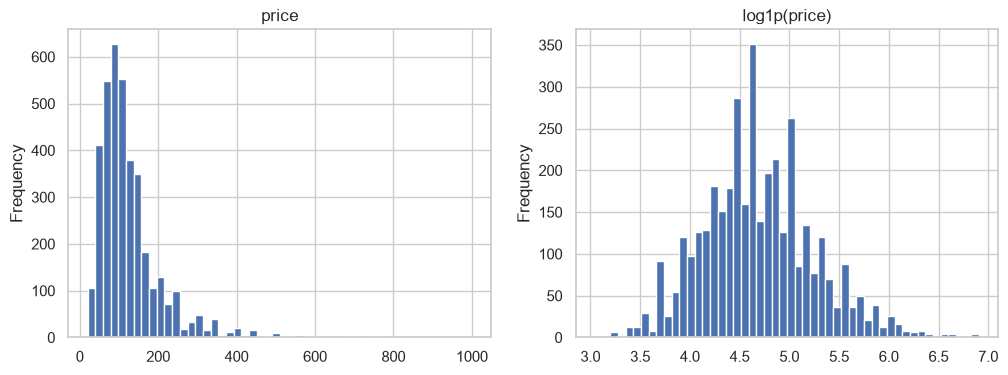

In [46]:
price = listings["price"].str.replace(r"[\$,]", "", regex=True).astype(float)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
price.plot.hist(bins=50, ax=ax[0], title="price")
np.log1p(price).plot.hist(bins=50, ax=ax[1], title="log1p(price)")

### Value counts of categorical columns

In [47]:
for col in ["room_type", "property_type", "bed_type",
            "neighbourhood_group_cleansed", "cancellation_policy"]:
    print(f"--- {col} ---")
    print(listings[col].value_counts(dropna=False).to_string(), "\n")

--- room_type ---
room_type
Entire home/apt    2541
Private room       1160
Shared room         117 

--- property_type ---
property_type
House              1733
Apartment          1708
Townhouse           118
Condominium          91
Loft                 40
Bed & Breakfast      37
Other                22
Cabin                21
Camper/RV            13
Bungalow             13
Boat                  8
Tent                  5
Treehouse             3
Dorm                  2
Chalet                2
Yurt                  1
NaN                   1 

--- bed_type ---
bed_type
Real Bed         3657
Futon              74
Pull-out Sofa      47
Airbed             27
Couch              13 

--- neighbourhood_group_cleansed ---
neighbourhood_group_cleansed
Other neighborhoods    794
Capitol Hill           567
Downtown               530
Central Area           369
Queen Anne             295
Ballard                230
West Seattle           203
Rainier Valley         159
University District    122
Beaco

### Summary statistics of numeric columns

In [48]:
num_cols = ["accommodates", "bathrooms", "bedrooms", "beds", "minimum_nights", "guests_included"]
listings[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
accommodates,3818.0,3.349398,1.977599,1.0,2.0,3.0,4.0,16.0
bathrooms,3802.0,1.259469,0.590369,0.0,1.0,1.0,1.0,8.0
bedrooms,3812.0,1.307712,0.883395,0.0,1.0,1.0,2.0,7.0
beds,3817.0,1.735394,1.139480,1.0,1.0,1.0,2.0,15.0
minimum_nights,3818.0,2.369303,16.305902,1.0,1.0,2.0,2.0,1000.0
guests_included,3818.0,1.672603,1.311040,0.0,1.0,1.0,2.0,15.0


### Median price by room type

In [49]:
listings.assign(price=price).groupby("room_type")["price"].agg(["count", "median", "mean"]).round(1)

,count,median,mean
room_type,,,
Entire home/apt,2541,126.0,155.8
Private room,1160,69.0,75.0
Shared room,117,40.0,47.5


### Median price by neighbourhood group

In [50]:
listings.assign(price=price).groupby("neighbourhood_group_cleansed")["price"] \
       .agg(["count", "median", "mean"]).sort_values("median", ascending=False).round(1)

,count,median,mean
neighbourhood_group_cleansed,,,
Downtown,530,139.0,154.4
Magnolia,61,129.0,177.7
Queen Anne,295,119.0,157.2
Cascade,89,115.0,140.1
West Seattle,203,109.0,141.4
Capitol Hill,567,105.0,130.6
Central Area,369,100.0,128.3
Other neighborhoods,794,99.0,120.0
Ballard,230,95.0,124.7


### Correlation of numeric columns with price

In [51]:
listings.select_dtypes("number").assign(price=price).corr()["price"].sort_values(ascending=False).to_frame("corr")

,corr
price,1.000000
accommodates,0.652218
bedrooms,0.627720
beds,0.589525
square_feet,0.531752
bathrooms,0.516424
guests_included,0.392875
host_total_listings_count,0.093962
host_listings_count,0.093962
review_scores_location,0.075069


### Summary statistics of review scores

In [52]:
score_cols = ["review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness",
              "review_scores_checkin", "review_scores_communication",
              "review_scores_location", "review_scores_value"]
listings[score_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
review_scores_rating,3171.0,94.539262,6.606083,20.0,93.0,96.0,99.0,100.0
review_scores_accuracy,3160.0,9.636392,0.698031,2.0,9.0,10.0,10.0,10.0
review_scores_cleanliness,3165.0,9.556398,0.797274,3.0,9.0,10.0,10.0,10.0
review_scores_checkin,3160.0,9.786709,0.595499,2.0,10.0,10.0,10.0,10.0
review_scores_communication,3167.0,9.809599,0.568211,2.0,10.0,10.0,10.0,10.0
review_scores_location,3163.0,9.608916,0.629053,4.0,9.0,10.0,10.0,10.0
review_scores_value,3162.0,9.452245,0.750259,2.0,9.0,10.0,10.0,10.0


### Parse the amenities column

In [53]:
def parse_amenities(s):
    s = s.strip("{}")
    return [x.strip().strip('"') for x in re.findall(r'"[^"]*"|[^,]+', s) if x.strip()]

amen = listings["amenities"].map(parse_amenities)
amen.map(len).describe()

count    3818.000000
mean       14.358827
std         4.741425
min         0.000000
25%        11.000000
50%        14.000000
75%        17.000000
max        30.000000
Name: amenities, dtype: float64

### Most common amenities

In [54]:
pd.Series(Counter([a for lst in amen for a in lst]).most_common()).to_frame("item_count")

,item_count
0,"(Wireless Internet, 3667)"
1,"(Heating, 3627)"
2,"(Kitchen, 3423)"
3,"(Smoke Detector, 3281)"
4,"(Essentials, 3237)"
5,"(Dryer, 2997)"
6,"(Washer, 2992)"
7,"(Internet, 2811)"
8,"(Shampoo, 2670)"
9,"(TV, 2574)"


### Inspect the date columns

In [55]:
listings[["host_since", "first_review", "last_review"]].head(10)

,host_since,first_review,last_review
0,2011-08-11,2011-11-01,2016-01-02
1,2013-02-21,2013-08-19,2015-12-29
2,2014-06-12,2014-07-30,2015-09-03
3,2013-11-06,NaN,NaN
4,2011-11-29,2012-07-10,2015-10-24
5,2010-12-25,2015-06-11,2015-09-28
6,2012-05-30,2014-01-27,2015-12-07
7,2012-10-30,2013-01-03,2016-01-01
8,2012-04-18,2015-06-22,2015-08-17
9,2013-02-21,2014-04-27,2015-12-20


### Parse the date columns

In [56]:
for c in ["host_since", "first_review", "last_review"]:
    d = pd.to_datetime(listings[c], errors="coerce")
    print(f"{c:14s} {d.min()}  {d.max()}  nulls={d.isna().sum()}")

host_since     2008-11-10 00:00:00  2016-01-03 00:00:00  nulls=2
first_review   2009-06-07 00:00:00  2016-01-03 00:00:00  nulls=627
last_review    2011-09-17 00:00:00  2016-01-03 00:00:00  nulls=627


### Conclusion on Listings.csv

- 3,818 rows x 92 columns; one row per listing, target is `price`.
- `price` is right-skewed: median 100, mean 128, range 20-1,000. Train on `log1p(price)`, evaluate after `expm1`.
- `room_type` is the strongest single feature. Median price: entire home 126, private room 69, shared room 40.
- Highest missing rates: `license` 100%, `square_feet` 97.5%, `monthly_price` 60.3%, `security_deposit` 51.1%, `weekly_price` 47.4%, `cleaning_fee` 27.0%, `host_acceptance_rate` 20.2%.
- Drop entirely: `license`, `square_feet`, `requires_license`, `jurisdiction_names`, `experiences_offered`, `has_availability`, `host_acceptance_rate`, and every id / url / long-text column.
- Needs parsing: `price` family (`$` and `,`), `host_response_rate` (`%`), `t`/`f` booleans, `amenities` (`{...}` set, not JSON), and `host_since` / `first_review` / `last_review` (dates).
- Anomalies: `bathrooms` has 0 values; `bedrooms` = 0 is a studio (372 rows, keep it); `minimum_nights` reaches 1,000 (cap it).
- `review_scores_rating` is on a 0-100 scale while the other six scores are 0-10.
- Leakage: `weekly_price` and `monthly_price` are derived from `price` and must never be used as features.
- Categorical shape: `room_type` 3 values, `property_type` 16 values (90% House + Apartment, long tail needs grouping), `bed_type` 96% Real Bed (near-constant), `neighbourhood_group_cleansed` 17 values with `Other neighborhoods` as a catch-all bucket of 794 listings.


## Calendar.csv

### Explore few lines of calendar.csv

In [57]:
calendar.head(n=3)

,listing_id,date,available,price
0,241032,2016-01-04,t,$85.00
1,241032,2016-01-05,t,$85.00
2,241032,2016-01-06,f,NaN


### Shape of the dataframe

In [58]:
calendar.shape

(1393570, 4)

### List all columns with dtypes

In [59]:
calendar.dtypes.to_frame("dtype")

,dtype
listing_id,int64
date,str
available,str
price,str


### Count missing values per column

In [60]:
cal_nulls = pd.DataFrame({"nulls": calendar.isna().sum(), "pct": calendar.isna().mean()})
cal_nulls = cal_nulls.sort_values("pct", ascending=False)
cal_nulls["pct"] = (cal_nulls["pct"] * 100).round(1).astype(str) + "%"
cal_nulls

,nulls,pct
price,459028,32.9%
listing_id,0,0.0%
date,0,0.0%
available,0,0.0%


### Value counts of available

In [61]:
calendar["available"].value_counts(dropna=False).to_frame("count")

,count
available,
t,934542
f,459028


### Date range and coverage

In [62]:
print("range:", calendar["date"].min(), "->", calendar["date"].max())
print("days:", calendar["date"].nunique())
print("listings:", calendar["listing_id"].nunique())
print("every listing has 365 rows:", (calendar.groupby("listing_id").size() == 365).all())

range: 2016-01-04 -> 2017-01-02
days: 365
listings: 3818
every listing has 365 rows: True


### Inspect the price column

In [63]:
display(calendar["price"].head(5))
display(calendar.loc[calendar["price"].isna(), "available"].value_counts().to_frame("count"))

0    $85.00
1    $85.00
2       NaN
3       NaN
4       NaN
Name: price, dtype: str

,count
available,
f,459028


### Distribution of calendar price

In [64]:
cal_price = calendar["price"].str.replace(r"[\$,]", "", regex=True).astype(float)
cal_price.describe()

count    934542.000000
mean        137.944859
std         105.062870
min          10.000000
25%          75.000000
50%         109.000000
75%         160.000000
max        1650.000000
Name: price, dtype: float64

### Median price over time

<Axes: title={'center': 'median calendar price by date'}, xlabel='date'>

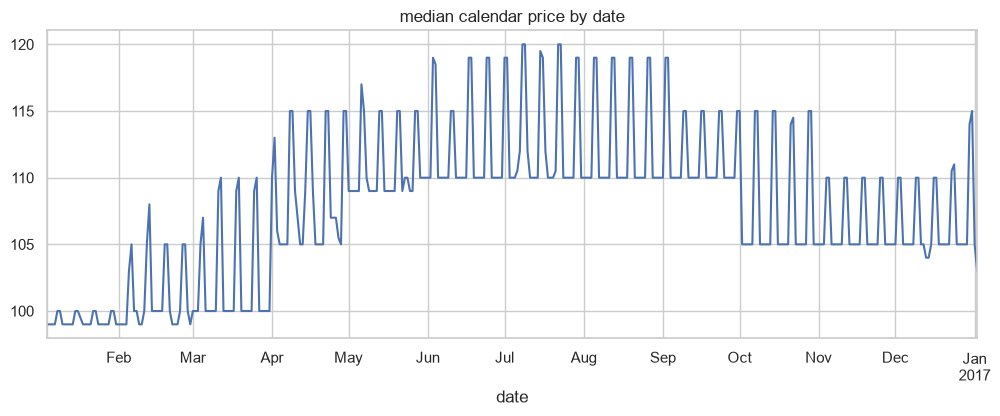

In [65]:
cal = calendar.assign(price_num=cal_price, date=pd.to_datetime(calendar["date"]))
cal.groupby("date")["price_num"].median().plot(figsize=(12, 4), title="median calendar price by date")

### Occupancy rate per listing

In [66]:
occ = calendar.assign(avail=calendar["available"].eq("t")).groupby("listing_id")["avail"].mean()
occ = (1 - occ).mul(100).round(1)
occ.describe().to_frame("occupancy_pct_365d")

,occupancy_pct_365d
count,3818.000000
mean,32.938318
std,34.733167
min,0.000000
25%,1.400000
50%,15.600000
75%,66.000000
max,100.000000


### Validate against availability_30

In [67]:
cal_dates = calendar.assign(date=pd.to_datetime(calendar["date"]))
first_30 = cal_dates[cal_dates["date"] < cal_dates["date"].min() + pd.Timedelta(days=30)]
calc_30 = first_30.assign(t=first_30["available"].eq("t")).groupby("listing_id")["t"].sum()
check = pd.DataFrame({"from_calendar": calc_30, "from_listings": listings.set_index("id")["availability_30"]}).dropna()
print("listings compared:", len(check))
print("exact match rate:", (check["from_calendar"] == check["from_listings"]).mean().round(3))
(check["from_calendar"] - check["from_listings"]).describe().to_frame("diff")

listings compared: 3818
exact match rate: 1.0


,diff
count,3818.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


### Conclusion on Calendar.csv

- 1,393,570 rows x 4 columns; one row per listing per day. 3,818 listings x 365 days, no gaps.
- Date range: 2016-01-04 to 2017-01-02. `available` is `t` for 934,542 rows (67.1%) and `f` for 459,028 rows (32.9%).
- `price` is missing for exactly 459,028 rows, and every one of them has `available == f`. Price is only quoted for bookable nights, so never impute it for unavailable dates.
- Calendar price: median 109, mean 138, min 10, max 1,650. Higher than `listings.price` (median 100) because it includes future premium nights.
- Occupancy proxy (1 - availability share) has median 15.6% but spreads from 0% to 100% (25% = 1.4%, 75% = 66%). Many hosts never update their calendar, so treat availability as a weak signal.
- Validation: available days in the first 30 days derived from `calendar` match `listings.availability_30` exactly for all 3,818 listings. The aggregation is verified.
- Features to build: occupancy over 30 / 90 / 365 days, median calendar price, weekend-to-weekday price ratio.

## Reviews.csv

### Explore few lines of reviews.csv

In [68]:
reviews.head(n=3)

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,7202016,38917982,2015-07-19,28943674,Bianca,Cute and cozy place. Perfect location to every...
1,7202016,39087409,2015-07-20,32440555,Frank,Kelly has a great room in a very central locat...
2,7202016,39820030,2015-07-26,37722850,Ian,"Very spacious apartment, and in a great neighb..."


### Shape of the dataframe

In [69]:
reviews.shape

(84849, 6)

### List all columns with dtypes

In [70]:
reviews.dtypes.to_frame("dtype")

,dtype
listing_id,int64
id,int64
date,str
reviewer_id,int64
reviewer_name,str
comments,str


### Count missing values per column

In [71]:
rev_nulls = pd.DataFrame({"nulls": reviews.isna().sum(), "pct": reviews.isna().mean()})
rev_nulls = rev_nulls.sort_values("pct", ascending=False)
rev_nulls["pct"] = (rev_nulls["pct"] * 100).round(1).astype(str) + "%"
rev_nulls

,nulls,pct
comments,18,0.0%
listing_id,0,0.0%
id,0,0.0%
date,0,0.0%
reviewer_id,0,0.0%
reviewer_name,0,0.0%


### Date range and coverage

In [72]:
rev_date = pd.to_datetime(reviews["date"])
print("range:", rev_date.min(), "->", rev_date.max())
print("listings reviewed:", reviews["listing_id"].nunique(), "of", listings.shape[0])

range: 2009-06-07 00:00:00 -> 2016-01-03 00:00:00
listings reviewed: 3191 of 3818


### Reviews per listing

In [73]:
reviews.groupby("listing_id").size().describe().to_frame("reviews_per_listing")

,reviews_per_listing
count,3191.000000
mean,26.590097
std,39.840788
min,1.000000
25%,4.000000
50%,13.000000
75%,31.000000
max,474.000000


### Reviews over time

<Axes: title={'center': 'reviews per month'}, xlabel='date'>

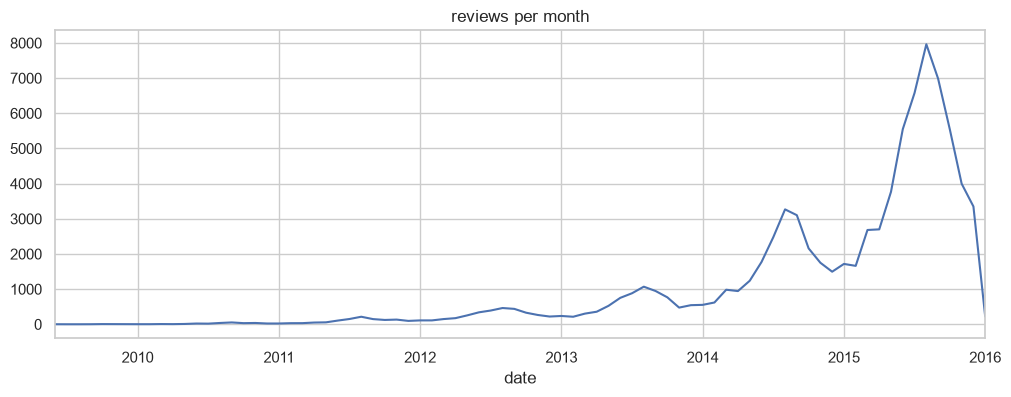

In [74]:
rev_date.dt.to_period("M").value_counts().sort_index().plot(
    figsize=(12, 4), title="reviews per month")

### Duplicate reviewers per listing

In [75]:
print("duplicated (listing_id, reviewer_id):", reviews.duplicated(["listing_id", "reviewer_id"]).sum())

duplicated (listing_id, reviewer_id): 1313


### Comment length

In [76]:
reviews["comments"].str.len().describe().to_frame("comment_length")

,comment_length
count,84831.000000
mean,385.033042
std,297.610952
min,1.000000
25%,191.000000
50%,313.000000
75%,491.000000
max,3472.000000


### Conclusion on Reviews.csv

- 84,849 rows x 6 columns; one row per review. Range 2009-06-07 to 2016-01-03.
- Covers 3,191 of 3,818 listings. 627 listings were never reviewed.
- Median 13 reviews per listing, 25th percentile 4, 75th percentile 31, max 474.
- 1,313 rows are duplicated on (`listing_id`, `reviewer_id`) and must be deduplicated.
- `comments` has 18 missing values; median length 313 characters, max 3,472.
- Monthly volume peaks at 3,998 in November 2015; January 2016 is partial (223) because the snapshot was taken on 2016-01-04.
- Features to build: total review count, reviews in the last 365 days, days since last review, mean comment length.